# Practica de Datos Médicos

![logo itq](img/ITQ.png)

**Nombre:** Robert Rosero

**Fecha:** 09-11-2026

# Paso 1: Descarga y registro de la fuente

***Celda 1: Instalación del paquete de descarga***

In [1]:
#Instalación del paquete de descarga
%pip install -q ucimlrepo

Note: you may need to restart the kernel to use updated packages.


**ucimlrepo:** Librería que sirve para descargar e importar conjuntos de datos en Python.

***Celda 2: Descarga y copia local***

In [5]:
# Importación Librerías
from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn import preprocessing
from datetime import date
 
# Descargar el conjunto de datos desde UCI.
dataset = fetch_ucirepo(id=296)
 
# Obtener una copia de todos los datos.
df = dataset.data.original.copy()
 
# Verificar que cumple con el tamaño solicitado.
print("Filas y columnas:", df.shape)
assert len(df) > 100_000, "El dataset debe superar los 100 000 registros."
 
# Visualizar los primeros registros.
display(df.head())
 
# Consultar el diccionario de variables.
display(dataset.variables)
 
# Guardar una copia local para desarrollar la actividad.
df.to_csv("hospitalizaciones_diabetes_original.csv", index=False)

# Información de la descarga
print("Fecha de descarga: ", date.today())
print("Versión de Pandas: ", pd.__version__)
print("Versión de Numpy: ", np.__version__)
print("Versión de Scikit-learn: ", sklearn.__version__)


C:\Users\roser\anaconda3\envs\Machine_Learning_2026\Lib\site-packages\ucimlrepo\fetch.py:97: DtypeWarning: Columns (10: payer_code) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(data_url)


Filas y columnas: (101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


,name,role,type,demographic,description,units,missing_values
0,encounter_id,ID,,NaN,Unique identifier of an encounter,None,no
1,patient_nbr,ID,,NaN,Unique identifier of a patient,None,no
2,race,Feature,Categorical,Race,"Values: Caucasian, Asian, African American, Hi...",None,yes
3,gender,Feature,Categorical,Gender,"Values: male, female, and unknown/invalid",None,no
4,age,Feature,Categorical,Age,"Grouped in 10-year intervals: [0, 10), [10, 20...",None,no
5,weight,Feature,Categorical,NaN,Weight in pounds.,None,yes
6,admission_type_id,Feature,Categorical,NaN,Integer identifier corresponding to 9 distinct...,None,no
7,discharge_disposition_id,Feature,Categorical,NaN,Integer identifier corresponding to 29 distinc...,None,no
8,admission_source_id,Feature,Categorical,NaN,Integer identifier corresponding to 21 distinc...,None,no
9,time_in_hospital,Feature,Integer,NaN,Integer number of days between admission and d...,None,no


Fecha de descarga:  2026-11-09
Versión de Pandas:  3.1.1
Versión de Numpy:  2.5.4
Versión de Scikit-learn:  1.9.1


**fetch:** Descarga e importa conjuntos de datos directamente desde el Repositorio  UCI a Python.

**pandas:** permite organizar, leer y manipular datos mediante tablas.

**numpy:** permite realizar operaciones matemáticas y trabajar con matrices.

**matplotlib.pyplot:** Para crear gráficos para visualizar los datos.

**seaborn:** Para crear gráficos estadísticos.

**sklearn:** Proporciona herramientas para el procesamiento de datos y Machine Learning.

**datetime:** Para registrar la fecha de descarga.

**assert:** Sirve para comprobar si una condicion se cumple, si no se cumple, Python muestra un mensaje de error.

**display:** Función que sirve para mejorar la visualización y organización de los datos.

**index=False:** Función que sirve para evitar guardar el índice de las filas como una columna adicional.



# Paso 2 Fase 1 Comprensión del negocio

**Problema:**

Las readmisiones hospitalarias representan un aspecto importante para los centros de salud, debido a que algunos pacientes necesitan regresar al hospital después de recibir atención médica. Por esta razón, es importante analizar los registros de hospitalización para conocer cómo se distribuyen sus características y estudiar de manera general su relación con las readmisiones.

**Actores interesados:**

- Hospitales y centros de salud.
- Personal médico.
- Investigadores.
- Analistas de datos.
- Instituciones relacionadas con la salud.

**Objetivo General:**

Analizar el conjunto de datos de hospitalizaciones de pacientes con diabetes mediante las fases de CRISP-DM, identificando sus características principales, evaluando la calidad de los datos y aplicando técnicas de normalización y estandarización a las variables cuantitativas.

**Preguntas de Analisis:**

¿Cómo se distribuyen las hospitalizaciones según la duración de la estancia hospitalaria?

¿Qué cantidad de hospitalizaciones presentan readmisiones antes o después de 30 días?

¿Cómo cambian las variables cuantitativas después de aplicar Min-Max y Z-score?

**Criterios de exito:**

-Descargar correctamente más de 100 000 registros.

-Identificar y documentar las características de las variables.

-Revisar los valores faltantes y duplicados.

-Aplicar correctamente las dos técnicas de transformación.

-Comprobar matemáticamente los resultados obtenidos.


**readmited:**

Esta variable contiene tres categorías:

- NO: No existe registro de readmisión.
- <30: El paciente fue readmitido antes de 30 días.
- '>30': El paciente fue readmitido después de 30 días.

**Límites del periodo, población y confidencialidad:**

El conjunto de datos incluye información sobre hospitalizaciones registradas entre 1999 y 2008. Por lo tanto, los resultados solo reflejan ese período y no necesariamente muestran la situación actual de los hospitales. Además, la información proviene de pacientes atendidos en centros médicos de Estados Unidos, por lo que no representa a toda la población ni a todos los sistemas de salud del mundo.

Es importante tener en cuenta que un mismo paciente puede aparecer más de una vez en los datos, ya que pudo haber sido hospitalizado en varias ocasiones durante este tiempo. Cada registro corresponde a un encuentro hospitalario, no necesariamente a una persona distinta.

Es fundamental respetar la confidencialidad de los datos médicos. La información debe usarse únicamente para fines académicos o estadísticos. No se debe intentar identificar a los pacientes ni revelar información personal.

# Paso 3 Fase 2 Comprensión de los datos

In [6]:
# Dimensiones del dataset

print("Número de hospitalizaciones: ", df.shape[0])
print("Número de columnas: ", df.shape[1])

# Consultar el número de pacientes únicos
print("Pacientes unicos: ", df["patient_nbr"].nunique())

Número de hospitalizaciones:  101766
Número de columnas:  50
Pacientes unicos:  71518


**shape[0]:** Devuelve la cantidad de filas.


**shape[1]:** Devuelve la cantidad de columnas.

**nunique:** Función que cuenta los valores diferentes de una columna.


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype
---  ------                    --------------   -----
 0   encounter_id              101766 non-null  int64
 1   patient_nbr               101766 non-null  int64
 2   race                      99493 non-null   str  
 3   gender                    101766 non-null  str  
 4   age                       101766 non-null  str  
 5   weight                    3197 non-null    str  
 6   admission_type_id         101766 non-null  int64
 7   discharge_disposition_id  101766 non-null  int64
 8   admission_source_id       101766 non-null  int64
 9   time_in_hospital          101766 non-null  int64
 10  payer_code                61510 non-null   str  
 11  medical_specialty         51817 non-null   str  
 12  num_lab_procedures        101766 non-null  int64
 13  num_procedures            101766 non-null  int64
 14  num_medications           10176

***Elaboración del diccionario para todas las columnas.***

In [42]:
# Crear una copia del diccionario de variables de UCI
diccionario = dataset.variables.copy()

# Agregar el tipo de dato observado en el DataFrame
diccionario["tipo_observado"] = diccionario["name"].map(df.dtypes.astype(str))

# Identificar las variables cuantitativas seleccionadas
variables_cuantitativas = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient"
]

# Definir el tipo conceptual de cada variable
def obtener_tipo_conceptual(nombre, tipo):
    if nombre in variables_cuantitativas:
        return "Cuantitativa"
    elif nombre in ["encounter_id", "patient_nbr"]:
        return "Identificador"
    else:
        return "Categórica"

diccionario["tipo_conceptual"] = diccionario.apply(
    lambda fila: obtener_tipo_conceptual(fila["name"], fila["type"]),
    axis=1
)

# Definir el rol analítico
def obtener_rol(nombre):
    if nombre == "readmitted":
        return "Variable objetivo"
    elif nombre in ["encounter_id", "patient_nbr"]:
        return "Identificador"
    elif nombre in variables_cuantitativas:
        return "Variable predictora"
    else:
        return "Variable descriptiva o predictora"

diccionario["rol_analitico"] = diccionario["name"].apply(obtener_rol)

# Mostrar el diccionario completo
display(diccionario)

,name,role,type,demographic,description,units,missing_values,tipo_observado,tipo_conceptual,rol_analitico
0,encounter_id,ID,,NaN,Unique identifier of an encounter,None,no,int64,Identificador,Identificador
1,patient_nbr,ID,,NaN,Unique identifier of a patient,None,no,int64,Identificador,Identificador
2,race,Feature,Categorical,Race,"Values: Caucasian, Asian, African American, Hi...",None,yes,str,Categórica,Variable descriptiva o predictora
3,gender,Feature,Categorical,Gender,"Values: male, female, and unknown/invalid",None,no,str,Categórica,Variable descriptiva o predictora
4,age,Feature,Categorical,Age,"Grouped in 10-year intervals: [0, 10), [10, 20...",None,no,str,Categórica,Variable descriptiva o predictora
5,weight,Feature,Categorical,NaN,Weight in pounds.,None,yes,str,Categórica,Variable descriptiva o predictora
6,admission_type_id,Feature,Categorical,NaN,Integer identifier corresponding to 9 distinct...,None,no,int64,Categórica,Variable descriptiva o predictora
7,discharge_disposition_id,Feature,Categorical,NaN,Integer identifier corresponding to 29 distinc...,None,no,int64,Categórica,Variable descriptiva o predictora
8,admission_source_id,Feature,Categorical,NaN,Integer identifier corresponding to 21 distinc...,None,no,int64,Categórica,Variable descriptiva o predictora
9,time_in_hospital,Feature,Integer,NaN,Integer number of days between admission and d...,None,no,int64,Cuantitativa,Variable predictora


**df.dtypes:** Obtiene el tipo de dato de cada columna del DataFrame.

**astype(str):** convierte esos tipos de datos en texto.

**.map():** relaciona cada nombre de variable con su tipo de dato.

**def:** Palabra que permite crear una función.

**.apply():** Aplica una operación a cada fila del diccionario.

**lambda:** Permite crear una pequeña función sin darle un nombre.

**axis:** Sirve para indicar como se realiza la operación en las filas.

***Identificación de datos faltantes***

In [8]:
# Contar los valores nulos
nulos = df.isnull().sum()

# Contar los marcadores de interrogación
interrogaciones = df.eq("?").sum()

# Crear una tabla de datos faltantes
faltantes = pd.DataFrame({
    "Valores nulos": nulos,
    "Marcadores ?": interrogaciones
})

# Calcular el total de faltantes
faltantes["Total faltantes"] = (
    faltantes["Valores nulos"] + faltantes["Marcadores ?"]
)

# Calcular el porcentaje de faltantes
faltantes["Porcentaje (%)"] = (
    faltantes["Total faltantes"] / len(df) * 100
).round(2)

# Mostrar resultados ordenados
display(faltantes.sort_values(
    by="Porcentaje (%)",
    ascending=False
))

,Valores nulos,Marcadores ?,Total faltantes,Porcentaje (%)
weight,98569,0,98569,96.86
max_glu_serum,96420,0,96420,94.75
A1Cresult,84748,0,84748,83.28
medical_specialty,49949,0,49949,49.08
payer_code,40256,0,40256,39.56
race,2273,0,2273,2.23
diag_3,1423,0,1423,1.40
diag_2,358,0,358,0.35
diag_1,21,0,21,0.02
patient_nbr,0,0,0,0.00


**isnull().sum():** Sirve para sumar los valores que son nulos.

**eq().sum():** Sirve para contar los marcadores que deseamos buscar.

**len():** Sirve para contar la cantidad de datos.

**round():** Sirve para definir la cantidad de decimales que deseamos.

**sort_values():** Función que permite ordenar los datos de una tabla según una columna específica.

**ascending:** Función que sirve para ordenar los datos de manera ascendente o descendente.

***Identificación de duplicados***

In [9]:
# Revisar filas duplicadas

print("Filas duplicadas: ", df.duplicated().sum())

# Revisar indetificadores de hospitalizacion repetidos

print("Encounter ID duplicados: ", df["encounter_id"].duplicated().sum())

# Revisar pacientes repetidos

print("Pacientes repetidos: ", df["patient_nbr"].duplicated().sum())

Filas duplicadas:  0
Encounter ID duplicados:  0
Pacientes repetidos:  30248


**duplicated().sum():** Sirve para sumar los datos duplicados.

***Calculo mínimo, media, máximo, mediana, desviación estandar y cuartiles***

In [10]:
# Seleccionar las siete variables solicitadas
variables = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient"
]

# Calcular estadísticas descriptivas
estadisticas = df[variables].describe().T

# Agregar la mediana
estadisticas["mediana"] = df[variables].median()

display(estadisticas)

,count,mean,std,min,25%,50%,75%,max,mediana
time_in_hospital,101766.0,4.395987,2.985108,1.0,2.0,4.0,6.0,14.0,4.0
num_lab_procedures,101766.0,43.095641,19.674362,1.0,31.0,44.0,57.0,132.0,44.0
num_procedures,101766.0,1.339730,1.705807,0.0,0.0,1.0,2.0,6.0,1.0
num_medications,101766.0,16.021844,8.127566,1.0,10.0,15.0,20.0,81.0,15.0
number_outpatient,101766.0,0.369357,1.267265,0.0,0.0,0.0,0.0,42.0,0.0
number_emergency,101766.0,0.197836,0.930472,0.0,0.0,0.0,0.0,76.0,0.0
number_inpatient,101766.0,0.635566,1.262863,0.0,0.0,0.0,1.0,21.0,0.0


***Analizar frecuencias de readmitted***

In [11]:
# Contar las categorías de readmisión
frecuencias = df["readmitted"].value_counts()

print(frecuencias)

# Calcular porcentajes
porcentajes = df["readmitted"].value_counts(normalize=True) * 100

display(porcentajes.round(2))

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64


readmitted
NO     53.91
>30    34.93
<30    11.16
Name: proportion, dtype: float64

**value_counts:** Sirve para contar cúantas veces aparece cada valor único.

**Gráfico 1: Histograma de duración hospitalaria**

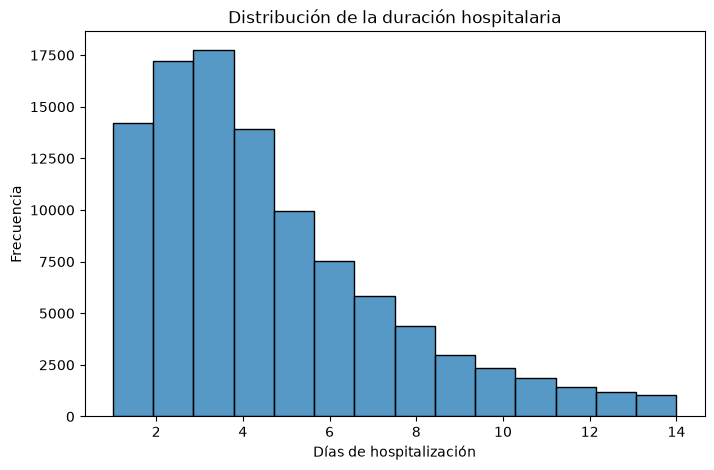

In [12]:
plt.figure(figsize=(8,5))

sns.histplot(data=df, x="time_in_hospital", bins=14)

plt.title("Distribución de la duración hospitalaria")
plt.xlabel("Días de hospitalización")
plt.ylabel("Frecuencia")

plt.show()

Se observa que la mayor concentración de hospitalizaciones se encuentra entre los 3 y 4 días, alcanzando aproximadamente 17 500 registros. Después de este intervalo, la frecuencia comienza a disminuir progresivamente.

**Gráfico 2: Diagrama de caja de duración hospitalaria**

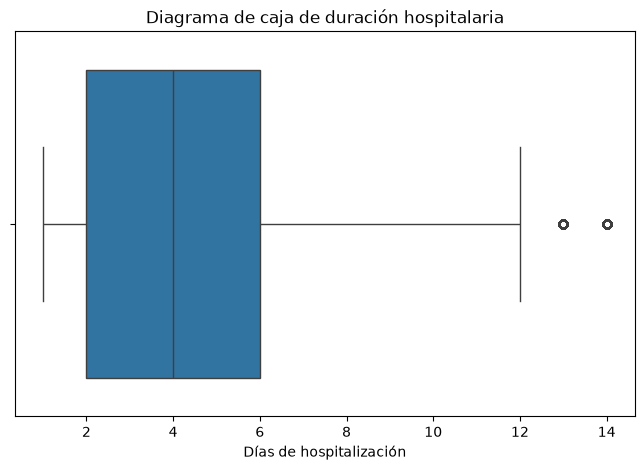

In [13]:
plt.figure(figsize=(8,5))

sns.boxplot(data=df, x="time_in_hospital")

plt.title("Diagrama de caja de duración hospitalaria")
plt.xlabel("Días de hospitalización")

plt.show()

La mayor concentración de los datos se encuentra entre los 2 y 6 días, con una mediana de 4 días. También se observan algunos valores atípicos por encima del límite superior, que representan hospitalizaciones de mayor duración.

**Gráfico 3: Histograma de medicamentos**

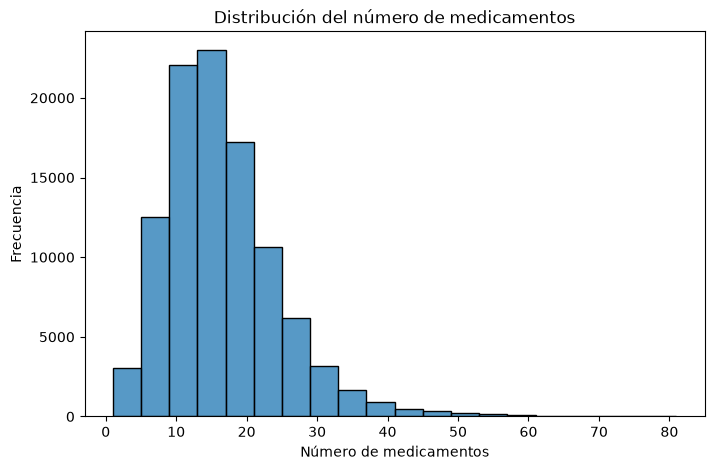

In [14]:
plt.figure(figsize=(8,5))

sns.histplot(data=df, x="num_medications", bins=20)

plt.title("Distribución del número de medicamentos")
plt.xlabel("Número de medicamentos")
plt.ylabel("Frecuencia")

plt.show()

Se observa una mayor concentración de registros entre 0 y 20 medicamentos aproximadamente. A partir de ese intervalo, la frecuencia comienza a disminuir, mostrando que existen menos hospitalizaciones con una cantidad elevada de medicamentos.

**Gráfico 4: Diagrama de caja de medicamentos**

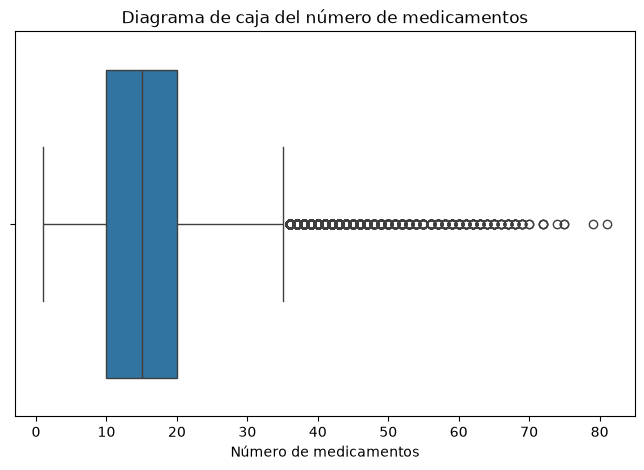

In [15]:
plt.figure(figsize=(8,5))

sns.boxplot(data=df, x="num_medications")

plt.title("Diagrama de caja del número de medicamentos")
plt.xlabel("Número de medicamentos")

plt.show()

La caja se encuentra aproximadamente entre 10 y 20 medicamentos, con una mediana cercana a 15. También se identifican numerosos valores atípicos por encima del límite superior, lo que indica que algunos registros presentan cantidades considerablemente mayores.

**Gráfico 5: Frecuencia de readmisiones**

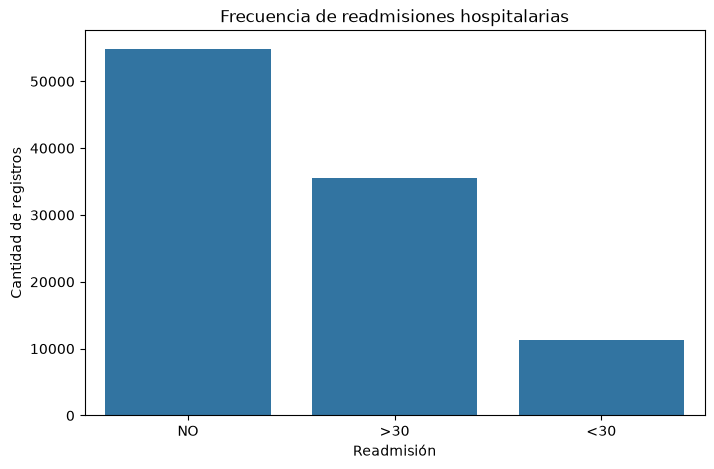

In [16]:
plt.figure(figsize=(8,5))

sns.countplot(data=df, x="readmitted")

plt.title("Frecuencia de readmisiones hospitalarias")
plt.xlabel("Readmisión")
plt.ylabel("Cantidad de registros")

plt.show()

La categoría NO presenta la mayor cantidad de registros, superando los 50 000. Le sigue la categoría >30, mientras que <30 presenta la menor frecuencia. Esto permite observar las diferencias en la distribución de las categorías de readmisión.

***Detección de valores atípicos (IQR)***

In [17]:
# Función para detectar valores atípicos
def detectar_atipicos(columna):

    Q1 = df[columna].quantile(0.25)
    Q3 = df[columna].quantile(0.75)

    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    atipicos = df[
        (df[columna] < limite_inferior) |
        (df[columna] > limite_superior)
    ]

    print("Variable:", columna)
    print("Cantidad de valores atípicos:", len(atipicos))
    print("Porcentaje:", round(len(atipicos) / len(df) * 100, 2), "%")
    print("--------------------------------")

# Analizar dos variables
detectar_atipicos("time_in_hospital")
detectar_atipicos("num_medications")

Variable: time_in_hospital
Cantidad de valores atípicos: 2252
Porcentaje: 2.21 %
--------------------------------
Variable: num_medications
Cantidad de valores atípicos: 2557
Porcentaje: 2.51 %
--------------------------------


Mediante el método IQR se identificaron valores atípicos en las dos variables analizadas. En time_in_hospital se encontraron 2 252 registros (2.21 %), mientras que en num_medications se encontraron 2 557 registros (2.51 %).

Estos valores se conservarán porque pueden representar situaciones reales de hospitalización y atención médica. Eliminarlos únicamente por superar los límites estadísticos podría provocar una pérdida innecesaria de información.

# Paso 4 Fase 3 Selección y limpieza Y Paso 5 Selección de variables cuantitativas

In [18]:
# Seleccionar las siete variables cuantitativas
variables = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient"
]

# Crear una copia de las variables seleccionadas
df_limpio = df[variables].copy()

# Mostrar las primeras filas
display(df_limpio.head())

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient
0,1,41,0,1,0,0,0
1,3,59,0,18,0,0,0
2,2,11,5,13,2,0,1
3,2,44,1,16,0,0,0
4,1,51,0,8,0,0,0


Utilizamos copy() para crear una copia independiente de las siete columnas. De esta manera, podemos trabajar con ellas sin modificar el dataset original.

In [19]:
# Consultar los tipos de datos
print("Tipos de datos:")
print(df_limpio.dtypes)

# Comprobar si existen valores nulos
print("\nValores nulos:")
print(df_limpio.isnull().sum())

Tipos de datos:
time_in_hospital      int64
num_lab_procedures    int64
num_procedures        int64
num_medications       int64
number_outpatient     int64
number_emergency      int64
number_inpatient      int64
dtype: object

Valores nulos:
time_in_hospital      0
num_lab_procedures    0
num_procedures        0
num_medications       0
number_outpatient     0
number_emergency      0
number_inpatient      0
dtype: int64


In [20]:
# Registrar las dimensiones antes de la limpieza
print("Dimensiones originales:", df.shape)

# Registrar las dimensiones después de seleccionar las variables
print("Dimensiones de los datos limpios:", df_limpio.shape)

# Comprobar los valores faltantes
print("Total de valores nulos:", df_limpio.isnull().sum().sum())

# Comprobar los registros duplicados en el dataset original
print("Filas duplicadas originales:", df.duplicated().sum())

Dimensiones originales: (101766, 50)
Dimensiones de los datos limpios: (101766, 7)
Total de valores nulos: 0
Filas duplicadas originales: 0


Durante la preparación de los datos se seleccionaron siete variables cuantitativas necesarias para el análisis. No fue necesario eliminar registros, debido a que estas variables no presentan valores faltantes y tampoco se encontraron filas completamente duplicadas en el conjunto original.

Se conservaron los identificadores y las demás variables en el dataset original, pero se excluyeron del proceso de escalamiento. También se conservaron los registros de pacientes repetidos, debido a que representan hospitalizaciones diferentes.

In [21]:
# Guardar una copia de las variables numéricas limpias
df_limpio.to_csv("variables_numericas_limpias.csv", index=False)

print("Archivo de variables numéricas limpias guardado correctamente.")

Archivo de variables numéricas limpias guardado correctamente.


# Paso 6 Normalización Min Max

In [22]:
# Seleccionamos las siete variables cuantitativas
X_train = df_limpio.to_numpy()

# Importamos preprocessing
from sklearn import preprocessing

# Creamos el objeto normalizer
normalizer = preprocessing.MinMaxScaler()

# Aplicamos la normalización
X_train_norm = normalizer.fit_transform(X_train)

# Mostramos los primeros 10 registros
print(X_train_norm[:10])

[[0.         0.30534351 0.         0.         0.         0.
  0.        ]
 [0.15384615 0.44274809 0.         0.2125     0.         0.
  0.        ]
 [0.07692308 0.07633588 0.83333333 0.15       0.04761905 0.
  0.04761905]
 [0.07692308 0.32824427 0.16666667 0.1875     0.         0.
  0.        ]
 [0.         0.38167939 0.         0.0875     0.         0.
  0.        ]
 [0.15384615 0.22900763 1.         0.1875     0.         0.
  0.        ]
 [0.23076923 0.52671756 0.16666667 0.25       0.         0.
  0.        ]
 [0.30769231 0.54961832 0.         0.1375     0.         0.
  0.        ]
 [0.92307692 0.51145038 0.33333333 0.3375     0.         0.
  0.        ]
 [0.84615385 0.24427481 0.5        0.2125     0.         0.
  0.        ]]


In [23]:
# Creamos una copia de los datos originales
X_train_2 = np.copy(X_train)

# Aplicamos el método fit
f = normalizer.fit(X_train_2)

# Aplicamos el método transform
X_train_norm_2 = f.transform(X_train_2)

# Comprobamos si los resultados son iguales
print(np.array_equiv(X_train_norm, X_train_norm_2))

True


In [24]:
# Consultamos los valores mínimos y máximos originales
print("Minimos originales:")
print(X_train.min(axis=0))

print("Maximos originales:")
print(X_train.max(axis=0))

# Consultamos los valores mínimos y máximos normalizados
print("Minimos normalizados:")
print(X_train_norm.min(axis=0))

print("Maximos normalizados:")
print(X_train_norm.max(axis=0))

Minimos originales:
[1 1 0 1 0 0 0]
Maximos originales:
[ 14 132   6  81  42  76  21]
Minimos normalizados:
[0. 0. 0. 0. 0. 0. 0.]
Maximos normalizados:
[1. 1. 1. 1. 1. 1. 1.]


In [25]:
# Comprobamos que los valores estén entre 0 y 1
print(np.all(X_train_norm >= 0))
print(np.all(X_train_norm <= 1))

True
False


La normalización Min-Max transformó las siete variables cuantitativas a una escala entre 0 y 1. Para ello, se usaron el valor mínimo y el valor máximo de cada columna como referencia. Este proceso ajusta los datos originales de manera que todos queden dentro del mismo rango, lo que facilita comparar variables que antes tenían escalas muy distintas.

Sin embargo, esta técnica puede verse afectada por valores extremos, ya que estos influyen directamente en el cálculo del mínimo y del máximo. Así, un valor muy alto o muy bajo puede alterar los límites de normalización y afectar los resultados.

Además, si una columna tiene todos los valores iguales, es decir, es constante, entonces el rango es cero. En este caso, Scikit-learn no realiza la división entre cero y asigna el valor 0 a todos los elementos de esa columna.

# Paso 7 Estandarización Z score

In [28]:
# Creamos el objeto standarizar
standarizar = preprocessing.StandardScaler()

# Aplicamos la estandarización
X_train_std = standarizar.fit_transform(X_train)

# Mostramos los primeros 10 registros
print(X_train_std[:10])

[[-1.13764856e+00 -1.06516859e-01 -7.85397739e-01 -1.84826769e+00
  -2.91461485e-01 -2.12620184e-01 -5.03276193e-01]
 [-4.67652708e-01  8.08383873e-01 -7.85397739e-01  2.43389649e-01
  -2.91461485e-01 -2.12620184e-01 -5.03276193e-01]
 [-8.02650635e-01 -1.63135141e+00  2.14578066e+00 -3.71803686e-01
   1.28674802e+00 -2.12620184e-01  2.88579047e-01]
 [-8.02650635e-01  4.59665961e-02 -1.99162059e-01 -2.68768505e-03
  -2.91461485e-01 -2.12620184e-01 -5.03276193e-01]
 [-1.13764856e+00  4.01761326e-01 -7.85397739e-01 -9.86997022e-01
  -2.91461485e-01 -2.12620184e-01 -5.03276193e-01]
 [-4.67652708e-01 -6.14795044e-01  2.73201634e+00 -2.68768505e-03
  -2.91461485e-01 -2.12620184e-01 -5.03276193e-01]
 [-1.32654781e-01  1.36748988e+00 -1.99162059e-01  6.12505651e-01
  -2.91461485e-01 -2.12620184e-01 -5.03276193e-01]
 [ 2.02343146e-01  1.51997333e+00 -7.85397739e-01 -4.94842354e-01
  -2.91461485e-01 -2.12620184e-01 -5.03276193e-01]
 [ 2.88232656e+00  1.26583424e+00  3.87073620e-01  1.47377632e+0

In [29]:
# Creamos una copia de los datos originales
X_train_2 = np.copy(X_train)

# Aplicamos el método fit
f = standarizar.fit(X_train_2)

# Aplicamos el método transform
X_train_std_2 = f.transform(X_train_2)

# Comprobamos si los resultados son iguales
print(np.array_equiv(X_train_std, X_train_std_2))

True


In [30]:
# Consultamos las medias originales
print("Medias originales:")
print(X_train.mean(axis=0))

# Consultamos las desviaciones estándar originales
print("Desviaciones estandar originales:")
print(X_train.std(axis=0))

# Consultamos las medias estandarizadas
print("Medias estandarizadas:")
print(X_train_std.mean(axis=0))

# Consultamos las desviaciones estándar estandarizadas
print("Desviaciones estandarizadas:")
print(X_train_std.std(axis=0))

Medias originales:
[ 4.39598687 43.09564098  1.33973036 16.02184423  0.36935715  0.19783621
  0.63556591]
Desviaciones estandar originales:
[ 2.9850931  19.67426558  1.7057986   8.12752628  1.26725887  0.9304677
  1.26285709]
Medias estandarizadas:
[ 5.80912639e-17  1.16182528e-16 -6.47941020e-17 -1.34056763e-16
  3.57484701e-17  1.78742350e-17 -3.57484701e-17]
Desviaciones estandarizadas:
[1. 1. 1. 1. 1. 1. 1.]


Al aplicar StandardScaler, pueden aparecer valores negativos cuando los datos están por debajo de la media y positivos cuando están por encima. A diferencia de MinMaxScaler, los resultados no están limitados al intervalo [0, 1]. En las columnas constantes, todos los valores estandarizados son 0 porque no existe variación y su desviación estándar es 0.

# Paso 8 Comparación y exportación

***Comparación de los primeros registros***

In [31]:
# Mostramos los primeros 10 registros normalizados
print("Datos normalizados:")
print(X_train_norm[:10])

# Mostramos los primeros 10 registros estandarizados
print("Datos estandarizados:")
print(X_train_std[:10])

Datos normalizados:
[[0.         0.30534351 0.         0.         0.         0.
  0.        ]
 [0.15384615 0.44274809 0.         0.2125     0.         0.
  0.        ]
 [0.07692308 0.07633588 0.83333333 0.15       0.04761905 0.
  0.04761905]
 [0.07692308 0.32824427 0.16666667 0.1875     0.         0.
  0.        ]
 [0.         0.38167939 0.         0.0875     0.         0.
  0.        ]
 [0.15384615 0.22900763 1.         0.1875     0.         0.
  0.        ]
 [0.23076923 0.52671756 0.16666667 0.25       0.         0.
  0.        ]
 [0.30769231 0.54961832 0.         0.1375     0.         0.
  0.        ]
 [0.92307692 0.51145038 0.33333333 0.3375     0.         0.
  0.        ]
 [0.84615385 0.24427481 0.5        0.2125     0.         0.
  0.        ]]
Datos estandarizados:
[[-1.13764856e+00 -1.06516859e-01 -7.85397739e-01 -1.84826769e+00
  -2.91461485e-01 -2.12620184e-01 -5.03276193e-01]
 [-4.67652708e-01  8.08383873e-01 -7.85397739e-01  2.43389649e-01
  -2.91461485e-01 -2.12620184e-01 

***Comparación de las estadísticas***

In [32]:
# Consultamos las medias de los datos normalizados
print("Medias normalizadas:")
print(X_train_norm.mean(axis=0))

# Consultamos las medias de los datos estandarizados
print("Medias estandarizadas:")
print(X_train_std.mean(axis=0))

# Consultamos las desviaciones estándar normalizadas
print("Desviaciones estandar normalizadas:")
print(X_train_norm.std(axis=0))

# Consultamos las desviaciones estándar estandarizadas
print("Desviaciones estandar estandarizadas:")
print(X_train_std.std(axis=0))

Medias normalizadas:
[0.26122976 0.32134077 0.22328839 0.18777305 0.00879422 0.00260311
 0.03026504]
Medias estandarizadas:
[ 5.80912639e-17  1.16182528e-16 -6.47941020e-17 -1.34056763e-16
  3.57484701e-17  1.78742350e-17 -3.57484701e-17]
Desviaciones estandar normalizadas:
[0.22962255 0.15018523 0.28429977 0.10159408 0.03017283 0.012243
 0.06013605]
Desviaciones estandar estandarizadas:
[1. 1. 1. 1. 1. 1. 1.]


La normalización transforma los datos para que sus valores se encuentren dentro de un rango de 0 a 1, mientras que la estandarización transforma los datos tomando como referencia la media y la desviación estándar. Ambos métodos permiten preparar las variables numéricas para utilizarlas posteriormente en modelos de Machine Learning.

***Gráficos comparativos***

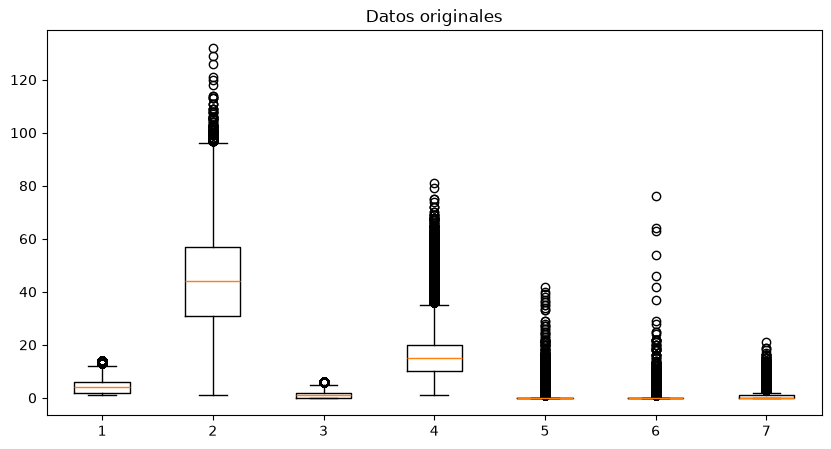

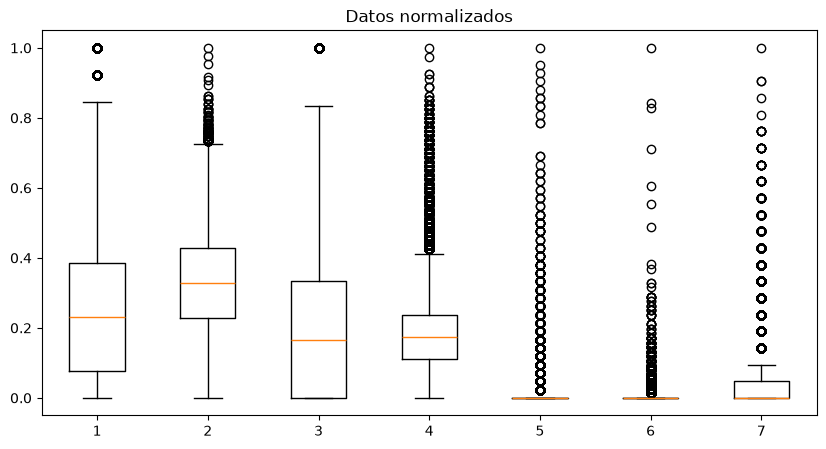

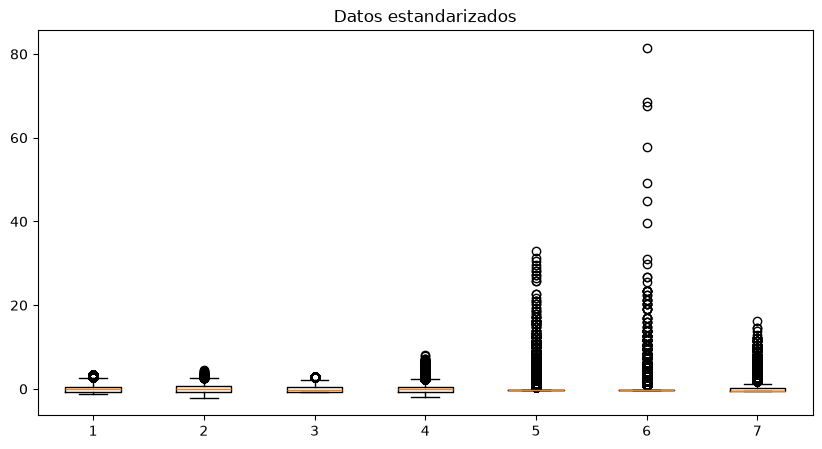

In [33]:
# Importamos matplotlib
import matplotlib.pyplot as plt

# Graficamos los datos originales
plt.figure(figsize=(10,5))
plt.boxplot(X_train)
plt.title("Datos originales")
plt.show()

# Graficamos los datos normalizados
plt.figure(figsize=(10,5))
plt.boxplot(X_train_norm)
plt.title("Datos normalizados")
plt.show()

# Graficamos los datos estandarizados
plt.figure(figsize=(10,5))
plt.boxplot(X_train_std)
plt.title("Datos estandarizados")
plt.show()

Interpretación de los datos:

- Datos originales: Las siete variables tienen escalas diferentes, algunas presentan variables mucho más grandes que las otras, también se observan varios valores atípicos.

- Datos normalizados: Todas las variables quedan dentro del rango de 0 a 1, siguen habiendo valores atípicos, las diferencias de escala entre las variables se reducen.

- Datos estandarizados: Los valores se encuentran centrados alrededor de 0, algunos son positivos o negativos.

***Selección de cinco variables:***

In [34]:
# Seleccionamos los primeros cinco valores
print(X_train[:5, 0])

[1 3 2 2 1]


***Cálculo manual de la normalización***

In [35]:
# Seleccionamos los primeros cinco valores
datos = X_train[:5, 0]

# Aplicamos la formula de normalizacion
datos_norm = (datos - X_train[:, 0].min()) / (X_train[:, 0].max() - X_train[:, 0].min())

# Mostramos los resultados
print("Valores originales:")
print(datos)

print("Valores normalizados manualmente:")
print(datos_norm)

Valores originales:
[1 3 2 2 1]
Valores normalizados manualmente:
[0.         0.15384615 0.07692308 0.07692308 0.        ]


***Cálculo manual de la estandarización***

In [36]:
# Calculamos la media y desviacion estandar
media = X_train[:, 0].mean()
desviacion = X_train[:, 0].std()

# Aplicamos la formula de estandarizacion
datos_std = (datos - media) / desviacion

# Mostramos los resultados
print("Valores originales:")
print(datos)

print("Valores estandarizados manualmente:")
print(datos_std)

Valores originales:
[1 3 2 2 1]
Valores estandarizados manualmente:
[-1.13764856 -0.46765271 -0.80265063 -0.80265063 -1.13764856]


# Exportación de los archivos CSV

***Exportar los archivos normalizados***

In [37]:
# Creamos un DataFrame con los datos normalizados
df_normalizado = pd.DataFrame(X_train_norm, columns=variables)

# Guardamos los datos en un archivo CSV
df_normalizado.to_csv("datos_normalizados.csv", index=False)

***Exportar los archivos estandarizados***

In [38]:
# Creamos un DataFrame con los datos estandarizados
df_estandarizado = pd.DataFrame(X_train_std, columns=variables)

# Guardamos los datos en un archivo CSV
df_estandarizado.to_csv("datos_estandarizados.csv", index=False)

- df_normalizado.csv: Contiene las siete variables con valores entre 0 y 1.

- df_estandarizado.csv: Contiene las mismas siete variables, pero con valores estandarizados.

-Los nombres de las columnas se conservaron correctamente.

-Los valores coinciden con los resultados que obtuvimos en los pasos anteriores.

# Preguntas de análisis y reflexión
1. ¿Cómo se distribuyen las hospitalizaciones según la duración de la estancia hospitalaria?

Las hospitalizaciones tienen una duración de entre 1 y 14 días. La mayor concentración se encuentra aproximadamente entre 2 y 6 días, con un promedio de 4,39 días y una mediana de 4 días. Esto indica que la mayoría de los pacientes permanece hospitalizada durante períodos relativamente cortos.

2. ¿Qué cantidad de hospitalizaciones presentan readmisiones antes o después de 30 días?

Según los resultados obtenidos:
- Readmisiones antes de 30 días (<30): 11.357 hospitalizaciones (11,16 %).
- Readmisiones después de 30 días (>30): 35.545 hospitalizaciones (34,93 %).
- Sin readmisión (NO): 54.864 hospitalizaciones (53,91 %).
Podemos observar que la mayoría de las hospitalizaciones no presenta una readmisión registrada. 

3. ¿Cómo cambian las variables cuantitativas después de aplicar Min-Max y Z-score?

Después de aplicar MinMaxScaler, los valores de las siete variables se transforman a un rango entre 0 y 1. En cambio, al aplicar StandardScaler, los valores se transforman tomando como referencia la media y la desviación estándar, obteniendo medias cercanas a 0 y desviaciones estándar iguales a 1.

4. ¿Qué diferencias existen entre la normalización y la estandarización?

La principal diferencia es que la normalización limita los valores a un rango determinado, en este caso de 0 a 1, mientras que la estandarización centra los datos alrededor de cero. Ambos métodos permiten trabajar con variables que originalmente tienen escalas diferentes.

5. ¿Por qué es importante realizar la preparación y transformación de los datos antes de aplicar un modelo de Machine Learning?

Porque permite organizar y preparar los datos para que puedan ser utilizados correctamente por los algoritmos de Machine Learning. También ayuda a evitar que las diferencias de escala entre las variables afecten determinados modelos y facilita su posterior análisis.

# Conclusiones

***Respuesta de las preguntas iniciales:***

1. ¿Cómo se distribuyen las hospitalizaciones según la duración de la estancia hospitalaria?

   La mayoría duró entre 2 y 6 días, con un promedio aproximado de 4,4 días.

2. ¿Qué cantidad de hospitalizaciones presentan readmisiones antes o después de 30 días?

   Se registraron 11.357 readmisiones antes de 30 días (11,16 %) y 35.545 después de 30 días (34,93 %). El 53,91 % no presentó readmisiones.

3. ¿Cómo cambian las variables cuantitativas después de aplicar Min-Max y Z-score?

   Min-Max transforma los valores al intervalo [0, 1], mientras que Z-score centra los datos alrededor de cero y establece una desviación estándar aproximada de 1.


MinMaxScaler es conveniente cuando se necesita un rango definido, mientras que StandardScaler resulta útil cuando se necesita centrar los datos considerando su dispersión. El análisis presenta limitaciones debido a los valores faltantes y atípicos, además de que los registros corresponden a hospitales de Estados Unidos entre 1999 y 2008, por lo que no representan necesariamente la situación actual.

Para realizar esta actividad decidí tomar como referencia el conjunto de datos publicado en UCI Machine Learning Repository. También utilicé ChatGPT para aclarar algunas dudas, comprender ciertos fragmentos de código y mejorar la redacción de las explicaciones y conclusiones.

Fuente: https://archive.ics.uci.edu/dataset/296/diabetes+130+us+hospitals+for+years+1999+2008?utm_source